In [ ]:

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import BaseMessage, AnyMessage, ToolMessage, SystemMessage
from typing import List, Optional, Any, Dict, Annotated, TypedDict
from langgraph.graph.message import add_messages
from pydantic import Field, BaseModel
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_groq import ChatGroq
from langgraph.types import interrupt, Command

class AgentState(TypedDict):
    # Full conversation so far
    messages: Annotated[List[AnyMessage], add_messages]

    # Field extraction bookkeeping
    on_project: Optional[int] = None
    tech_stack: Optional[List[str]] = None
    exp: Optional[int] = None
    degree_level: Optional[str] = None

    # Which fields are still missing? Used to decide if HITL tool is needed.
    missing_fields: List[str] = Field(default_factory=list)
    all_fields_present: bool = False
    ask_human: bool = None
    #No need to include others


    # For SQL generation
    db_name: Optional[str] = "employees"
    table: Optional[str] = "employees"
    fields: List[str] = Field(default_factory=list)
    limit: Optional[int] = 10

    sql_query: Optional[str] = None
    query_params: List[Any] = Field(default_factory=list)
    query_results: List[Dict[str, Any]] = Field(default_factory=list)

    # Final output
    results: List[Dict[str, Any]] = Field(default_factory=list)


In [2]:
from langchain_core.tools import tool
from pydantic import BaseModel, Field

class SQLToolInput(BaseModel):
    """Description of fields required to call the sql_tool""" 
    db_name: str
    exp: int  # REQUIRED
    on_project: int  # REQUIRED
    tech_stack: list  # REQUIRED
    degree_level: str  # REQUIRED
    limit: int = 10  # OPTIONAL, default 10

@tool(args_schema=SQLToolInput)
def generate_sql_query_and_fetch_db_results(
    db_name: str,
    exp: int ,
    on_project: int ,
    tech_stack: list ,
    degree_level: str ,
    limit: int = 10
) -> str:
    """
    Generates and executes a SQL query on the `employees` table to find suitable employees for internal project allocation.

    Use this tool when the user is asking to find employees based on filters like:
    - Minimum years of experience (`exp`)
    - Whether the employee is currently available or occupied (`on_project`)
    - Required technical skills (`tech_stack`)
    - Educational qualification (`degree_level`)

    This tool returns a list of matching employees directly from the database.
    """
    from psycopg2.extensions import adapt
    import psycopg2
    import json
    from database.config_db import discover_databases
    from langchain.prompts import ChatPromptTemplate
    from langchain_groq import ChatGroq

    TOOL_PROMPT = """
        You are an expert PostgreSQL query generator. Based on the inputs below, return a parameterized SELECT query using %s placeholders.

        Mandatory always use table_name as *employees* nothing else neither employee_databse nor anything

        - exp → use exp >= %s
        - on_project → on_project = %s
        - tech_stack → tech_stack @> %s
        - degree_level → degree_level = %s
        Always include a LIMIT %s clause.
        Only include filters for non-null fields.

        Inputs:
        - exp: {exp}
        - on_project: {on_project}
        - tech_stack: {tech_stack}
        - degree_level: {degree_level}
        - limit: {limit}

        Respond ONLY with a JSON object: {{"query": "...", "params": [...]}} — no markdown, no explanations.
        """

    prompt = ChatPromptTemplate.from_template(TOOL_PROMPT)
    llm = ChatGroq(model="llama-3.3-70b-versatile", temperature=0.0)
    chain = prompt | llm

    response = chain.invoke({
    "exp": exp,
    "on_project": on_project,
    "tech_stack": tech_stack,
    "degree_level": degree_level,
    "limit": limit
})

    response_text = response.content.strip().strip("`")
    if response_text.startswith("json"):
        response_text = response_text[len("json"):].strip()

    print("[🧠 LLM Raw Response]", repr(response_text))

    try:
        parsed = json.loads(response_text)
    except json.JSONDecodeError as e:
        raise ValueError(f"❌ Failed to parse LLM response: {e}\nRaw: {response_text}")

    query = parsed["query"]
    params = parsed["params"]
    try:
        db = discover_databases()["employees"]
        conn = psycopg2.connect(
            host=db["host"], port=db["port"], dbname=db["dbname"],
            user=db["owner"], password=db["password"]
        )

        # Ensure list-type (tech_stack) params are kept as native Python lists
        clean_params = []
        for p in params:
            if isinstance(p, str) and p.startswith("{") and p.endswith("}"):
                p = p.strip("{}").split(",")
                p = [x.strip(" \"'") for x in p]
            clean_params.append(p)

        print("[Running Query]")
        print("SQL Query:", query)
        print("Params:", clean_params)

        with conn, conn.cursor() as cur:
            cur.execute(query, clean_params)
            cols = [desc.name for desc in cur.description]
            rows = [dict(zip(cols, row)) for row in cur.fetchall()]

    except Exception as err:
        print(f"[resource_allocator] ⚠ {err} — using fallback")
        rows = [
            {"id": 999, "first_name": "Stub", "last_name": "User", "on_project": 0,
             "exp": 42, "tech_stack": ["python", "sql"], "degree_level": "PhD"}
        ]

    return json.dumps({"results": rows})


# HITL
class HumanAssistSchema(BaseModel):
    "Request assistance from a human to collect all the parameter values required one by one before generating the sql query."

    query: str = Field(default=None, description="Request query to ask user to enter the parameter value")

@tool("human_assistance_tool", args_schema=HumanAssistSchema)
async def human_assistance(query: str):


    return ""



In [3]:
#  If `degree_level` is missing, ask: "What is the degree level? (Bachelor, Master, or PhD)"
#       - **Normalize the user’s input**:
#          - Any input containing *bachelor*, *BACHELOR*, *bachelo'r*, etc. → **map to `Bachelor`**
#          - Any input containing *master*, *masters*, *Master*, etc. → **map to `Master`**
#          - Any input containing *phd*, *PHD*, *Ph.D.*, *PhD*, etc. → **map to `PhD`**
#   - Always use **exactly** `Bachelor`, `Master`, or `PhD` in the final query.

#    If the user input is unclear or ambiguous, clarify with the `human_assistance_tool` again until you have a clear, valid value.

In [4]:
from langchain.prompts import ChatPromptTemplate
import re 

# SYSTEM_PROMPT = """
# You are a virtual assistant for Ascent, specialized in Resource Allocation ONLY.

# Help in generating SQL queries, fetch DB results, or call a human assistance tool if some value is required from the human.
# If information is missing, ask via human_assistance_tool.
# Always use database name: ```employees```
# If the user asks for the DB schema, call the DB schema tool.
# If you have to genearted the SQL query call the sql query and db fetch tool.
# Do NOT answer anything unrelated to Resource Allocation.
# """




#- Simply output the final results in valid **JSON only**, with this format:
   #   ```json
   #   {
   #     "results": [...]
   #   }
   #   ```
   # - Do not add any text, commentary, or explanation. The final output must be pure JSON.




# SYSTEM_PROMPT ="""
# You are a virtual assistant for Ascent, specialized ONLY in **Resource Allocation** tasks.

# Your job:
# 1️⃣ Extract all possible fields from the user query related to allocating employees to internal projects.
#    - The employee table has these fields: `exp` (integer), `tech_stack` (list of strings), `on_project` (0 if available, 1 if occupied), `degree_level` (string).
#    - If the user mentions something implicitly (e.g., "available"), map that correctly (e.g., `on_project = 0`).
#    - Return all extracted fields clearly in the tool call arguments.

# 2️⃣ If any required field (`exp`, `tech_stack`, `on_project`, `degree_level`) is missing, immediately call the `human_assistance_tool` with a clear `query` asking for that specific field.
#    - Example: If `on_project` is missing, ask: "Is the employee currently available or occupied?"
#    - Ask only one missing field at a time.

# 3️⃣ If all required fields are present, generate a SELECT SQL query using the tool `generate_sql_query_and_fetch_db_results`.
#    - Always use parameterized placeholders (%s) for inputs.
#    - Only filter on fields that are actually provided.
#    - Always include LIMIT 10.

# ⚠️ Strict rules:
# - If you need more information, do NOT guess — always ask the human using `human_assistance_tool`.
# - Do NOT answer anything unrelated to Resource Allocation.
# - NEVER fabricate field values.

# Your output must always:
# - Call the correct tool(s) with exact arguments.
# - Include ALL extracted field values in tool arguments.


# """

SYSTEM_PROMPT="""
You are a virtual assistant for Ascent, specialized ONLY in **Resource Allocation** tasks.

Always use db_name for sql_query tool as *employees*

Your job:
1️⃣ Extract all possible fields from the user query related to allocating employees to internal projects.
   - The employee table has these fields: `exp` (integer), `tech_stack` (list of strings), `on_project` (0 if available, 1 if occupied), `degree_level` (string).
   - If the user mentions something implicitly (e.g., "available"), map that correctly (e.g., `on_project = 0`).
   - Include **only** valid fields in the tool call arguments.

2️⃣ If any required field (`exp`, `tech_stack`, `on_project`, `degree_level`) is missing, immediately call the `human_assistance_tool` with a clear `query` asking for that specific field.
   
   - Immediately call the `human_assistance_tool` with a clear `query` asking only for that specific missing field.
      - Example: If `on_project` is missing, ask: "Is the employee currently available or occupied?"
         - If the user says "available", map that to `on_project = 0` (meaning available).
         - If the user says "occupied", map that to `on_project = 1` (meaning assigned).

   - If `degree_level` is missing, ask: "What is the degree level? (Bachelor, Master, or PhD)"
      **Normalize the user’s input**:
         - Any spelling or casing that means *bachelor* → `Bachelor`
         - Any spelling or casing that means *master* → `Master`
         - Any spelling or casing that means *phd* → `PhD`
         - Always use **exactly** `Bachelor`, `Master`, or `PhD` in the final query.
         
   If the user input is unclear or ambiguous, clarify with the `human_assistance_tool` again until you have a clear, valid value.
   - Ask for only **one missing field at a time**.
   - ⚠️ You can use the `human_assistance_tool` **only before** the SQL query is generated.

3️⃣ Once all required fields are present:
   - Generate exactly **one** `generate_sql_query_and_fetch_db_results` tool call.
   - Use parameterized placeholders (`%s`) for inputs.
   - Filter only on fields that are actually provided.
   - Always include `LIMIT 10`.

4️⃣ After the SQL tool returns results:
   - **Do not** call any other tool.
   - **Do not** ask any more questions.
   - If the Tool Message contains `results` with employee data:
         - Read the JSON carefully.
         - Transform the JSON into a clear, friendly summary in natural language.
         - Mention the employee's full name, email, skills, experience, and project status in plain text.
         - Do not include any raw JSON in your answer.
   - If the Tool Message is empty or `[]`:
         - Politely say: "Sorry, no matching employees were found for your criteria."
         - Do not call any more tools.
   
⚠️ Behavioural Guidelines:
- If you need more information, never guess — always ask the human **before** the SQL tool is called.
- Do NOT answer anything unrelated to Resource Allocation.
- NEVER fabricate field values.
- After you get results from the SQL tool, your final message must contain **only JSON**.

 """
llm = ChatGroq(model="llama-3.3-70b-versatile", temperature=0.0)
tools = [generate_sql_query_and_fetch_db_results]
llm_with_tools = llm.bind_tools(tools + [human_assistance])



In [2]:
#print("Hi")

In [ ]:
import re
import json
import textwrap
from typing import Dict, Any
from langchain.prompts import ChatPromptTemplate
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage
from langgraph.types import interrupt

def _latest_user(state: AgentState) -> Optional[str]:
    # Helper to fetch the most recent user input message
    for msg in reversed(state.messages):
        if isinstance(msg, HumanMessage):
            return msg.content.strip()
    return None

EMPLOYEE_FIELDS = ["exp", "tech_stack", "on_project", "degree_level"]

field_extraction_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are an intelligent assistant that extracts structured field-value "
        "pairs from a user's natural language query. "
        f"Possible fields: {', '.join(EMPLOYEE_FIELDS)}. "
        "If the user says 'available', map that to `on_project=0`; "
        "if they say 'occupied', map that to `on_project=1`. "
        "**If the user says NOTHING about `on_project` or `degree_level`, do NOT include them in the JSON output.** "
        "For tech_stack, always return a list. Only include fields clearly stated or implied in the text."
    ),
    ("human", "{query}")
])



extractor_chain = field_extraction_prompt | llm | (lambda x: x.content.strip())

def _clean_llm_output(raw: str) -> str:
    raw = raw.strip().strip("`")
    match = re.search(r"\{[\s\S]*\}", raw)
    return match.group(0) if match else "{}"

# def call_model(state: AgentState) -> Dict:
#     msgs = state["messages"]
#     updates = {}

#     # 1️⃣ Look for latest user query
#     user_input = next((m.content for m in reversed(msgs) if isinstance(m, HumanMessage)), None)
#     if not user_input:
#         return {}

#     # 2️⃣ Extract fields from the input
#     raw = extractor_chain.invoke({"query": user_input})
#     print("[extractor]", raw)
#     json_text = _clean_llm_output(raw)
#     try:
#         extracted = json.loads(json_text)
#     except:
#         extracted = {}

#     # Normalize
#     if "tech_stack" in extracted and isinstance(extracted["tech_stack"], str):
#         extracted["tech_stack"] = [tok.strip() for tok in extracted["tech_stack"].split(",")]

#     missing = [f for f in EMPLOYEE_FIELDS if f not in extracted or extracted[f] in ("", None, [])]

#     if missing:
#         # Let LLM produce tool call for human_assistance_tool
#         prompt = ChatPromptTemplate.from_messages([
#             ("system", "Ask user for missing fields using human_assistance_tool."),
#             ("human", f"Missing fields: {missing}")
#         ])
#         response = prompt | llm_with_tools
#         output = response.invoke({"missing_fields": missing})
#         return {"messages": msgs + [output]}

#     # All fields present → run SQL tool
#     prompt = ChatPromptTemplate.from_messages([
#         ("system", "Call the SQL tool."),
#         ("human", f"Use these: {json.dumps(extracted)}")
#     ])
#     response = prompt | llm_with_tools
#     output = response.invoke(extracted)
#     return {"messages": msgs + [output]}

In [6]:

# def call_model(state: AgentState):
    
#     messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
#     response = llm_with_tools.invoke(messages)
#     print(response)
#     ask_human = False

#     if response.tool_calls:
#         if response.tool_calls[0]["name"] == "human_assistance_tool":
#             ask_human=True
#         elif response.tool_calls[0]["name"] == "generate_sql_query_and_fetch_db_results":
#             ask_human=False
#     return {"messages": [response], "ask_human": ask_human}


def call_model(state: AgentState):
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

from langchain_core.messages import SystemMessage
import json 

# def call_model(state: AgentState):
#     # 1️⃣ Add system prompt
#     messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]

#     # 2️⃣ Use extractor LLM to parse fields
#     last_user_message = state["messages"][-1].content
#     raw_extraction = extractor_chain.invoke({"query": last_user_message})
#     json_text = _clean_llm_output(raw_extraction)
#     try:
#         extracted = json.loads(json_text)
#     except Exception as e:
#         print(f"[extractor] ⚠️ Bad JSON: {e} raw: {json_text}")
#         extracted = {}

#     # 3️⃣ Figure out what’s missing
#     missing = [f for f in EMPLOYEE_FIELDS if f not in extracted or extracted[f] in (None, "", [])]

#     print("[extractor] Extracted:", extracted)
#     print("[extractor] Missing:", missing)

#     if missing:
#         return {
#             "messages": [],
#             "ask_human": True,
#             "missing_fields": missing
#         }

#     # 4️⃣ If all good → run main model + tools
#     response = llm_with_tools.invoke(messages)

#     ask_human = False
#     if response.tool_calls and response.tool_calls[0]["name"] == "human_assistance_tool":
#         ask_human = True

#     return {
#         "messages": [response],
#         "ask_human": ask_human
#     }


def tool_router(state: AgentState):
    if not state["all_fields_present"]:
        return "human_assistance"
    return tools_condition(state) ## tools if tool_call else __end__

def create_tool_message(response: str, tool_call_id: str):
    return ToolMessage(content=response, tool_call_id= tool_call_id)

In [7]:
def field_extractor_node(state: AgentState) -> Dict[str, Any]:
    user_msg = None
    for msg in reversed(state["messages"]):
        if msg.type == "human":
            user_msg = msg.content
            break

    if not user_msg:
        return {}

    try:
        raw_llm = extractor_chain.invoke({"query": user_msg})
        json_text = _clean_llm_output(raw_llm)
        extracted = json.loads(json_text)
    except Exception as err:
        print(f"[field_extractor] ⚠️ Cannot parse LLM output: {err}")
        extracted = {}

    updates: Dict[str, Any] = {k: v for k, v in extracted.items() if k in EMPLOYEE_FIELDS}

    missing = [f for f in EMPLOYEE_FIELDS if f not in updates]
    updates.update(
        missing_fields=missing,
        all_fields_present=len(missing) == 0,
    )
    return updates


In [8]:
from langgraph.types import interrupt
from langchain_core.messages import AIMessage
from langchain_core.messages import ToolMessage

# ✅ Your developer node EXACTLY as your working hitl_node:
from langgraph.types import interrupt
from langchain_core.messages import AIMessage, ToolMessage

def human_in_loop_node(state: AgentState) -> Dict[str, Any]:
    # 1️⃣ Extract the last human_assistance_tool call
    question = None
    for msg in reversed(state["messages"]):
        if isinstance(msg, AIMessage) and msg.tool_calls:
            for tc in msg.tool_calls:
                if tc["name"] == "human_assistance_tool":
                    question = tc["args"]["query"]
                    break
        if question:
            break

    if not question:
        question = "Please provide the missing information:"

    # 2️⃣ Ask the human
    answer = interrupt(question)

    # 3️⃣ Decide which field it’s for (optional)
    # If you use missing_fields tracking:
    field = state["missing_fields"][0] if state["missing_fields"] else "unknown_field"

    # Normalize
    if field in {"on_project", "exp"}:
        try:
            answer = int(answer)
        except Exception:
            pass
    elif field == "tech_stack":
        answer = [x.strip() for x in answer.split(",") if x.strip()]

    remaining = state["missing_fields"][1:] if state["missing_fields"] else []

    return {
        field: answer,
        "missing_fields": remaining,
        "all_fields_present": len(remaining) == 0,
        "messages": [
            AIMessage(content=question),
            HumanMessage(content=str(answer))
        ],
    }

# def human_in_loop_node(state: AgentState):
#     if not state["missing_fields"]:
#         return {}

#     field = state["missing_fields"][0]
#     question = f"Please provide a value for {field}:"
#     answer = interrupt(question)

#     # Type normalize
#     if field in {"on_project", "exp"}:
#         answer = int(answer)
#     elif field == "tech_stack":
#         answer = [x.strip() for x in answer.split(",") if x.strip()]

#     remaining = state["missing_fields"][1:]

#     return {
#         field: answer,
#         "missing_fields": remaining,
#         "all_fields_present": len(remaining) == 0,
#         "messages": [
#             AIMessage(content=question),
#             HumanMessage(content=str(answer))
#         ],
#     }

# def human_in_loop_node(state: AgentState):
#     if not state["missing_fields"]:
#         return {"ask_human": False}

#     field = state["missing_fields"][0]
#     question = "Please provide the value of {field}: "
#     answer = interrupt(question)

#     # Normalize types based on field type
#     if field in {"on_project", "exp"}:
#         try:
#             answer = int(answer)
#         except Exception:
#             pass
#     elif field == "tech_stack":
#         answer = [tok.strip() for tok in str(answer).split(",") if tok.strip()]

#     remaining = state.missing_fields[1:]

#     # Return only the updates (LangGraph merges this into full state)
#     return {
#         field: answer,
#         "missing_fields": remaining,
#         "all_fields_present": len(remaining) == 0,
#         "messages": [
#             AIMessage(content=question),
#             HumanMessage(content=str(answer)),
#         ],
#         "ask_human":False
#     }
    # new_messages = []
    # for msg in state["messages"][-1].tool_calls:
        # if msg["name"] == "human_assistance_tool":

        #     question = "Please provide the value of {field}: "
        #     #human_response = interrupt({"query": msg["args"]["query"]})
        #     new_messages.append(create_tool_message(
        #         response=human_response, tool_call_id=msg["id"])
        #     )
        # else:
        #     break
    
    # return {
    #     "messages": new_messages,
    #     "ask_human": False
    # }


In [9]:
graph = StateGraph(AgentState)

graph.add_node("extract_fields", field_extractor_node)
graph.add_node("call_model", call_model)

tool_node = ToolNode(tools=tools)
graph.add_node("tools", tool_node)

graph.add_node("human_assistance", human_in_loop_node)

graph.add_edge(START, "extract_fields")
graph.add_edge("extract_fields", "call_model")
graph.add_conditional_edges(
    "call_model",
    tool_router,
    {
        "human_assistance": "human_assistance",
        "tools": "tools",
        "__end__": "__end__",
    }
)
graph.add_edge("human_assistance", "call_model")
graph.add_edge("tools", "call_model")

#graph.set_entry_point("chatbot_node")
# graph.add_edge(START, "call model")

graph = graph.compile(checkpointer=MemorySaver())


In [10]:
tool_node

tools(tags=None, recurse=True, explode_args=False, func_accepts_config=True, func_accepts={'store': ('__pregel_store', None)}, tools_by_name={'generate_sql_query_and_fetch_db_results': StructuredTool(name='generate_sql_query_and_fetch_db_results', description='Generates and executes a SQL query on the `employees` table to find suitable employees for internal project allocation.\n\nUse this tool when the user is asking to find employees based on filters like:\n- Minimum years of experience (`exp`)\n- Whether the employee is currently available or occupied (`on_project`)\n- Required technical skills (`tech_stack`)\n- Educational qualification (`degree_level`)\n\nThis tool returns a list of matching employees directly from the database.', args_schema=<class '__main__.SQLToolInput'>, func=<function generate_sql_query_and_fetch_db_results at 0x000001FF14BDA5C0>)}, tool_to_state_args={'generate_sql_query_and_fetch_db_results': {}}, tool_to_store_arg={'generate_sql_query_and_fetch_db_results'

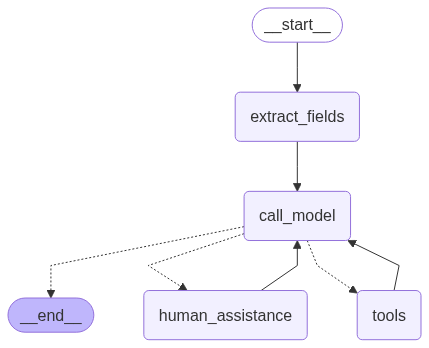

In [11]:
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

display(
    Image(
        graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [ ]:
messages = [HumanMessage(content="Find employee with Python, FastAPI, AWS, exp 4 years")]
result = graph.invoke({"messages": messages}, config={"configurable": {"thread_id": "demo"}})

while "__interrupt__" in result:
    prompt = result["__interrupt__"][0].value
    reply = input(prompt + " ")
    result = graph.invoke(Command(resume=reply), config={"configurable": {"thread_id": "demo"}})

print("\n✅ Final RESULT:", result)

[🧠 LLM Raw Response] '{"query": "SELECT * FROM employees WHERE exp >= %s AND on_project = %s AND tech_stack @> %s AND degree_level = %s LIMIT %s", "params": [4, 1, "{\'Python\', \'FastAPI\', \'AWS\'}", "Bachelor", 10]}'
[Running Query]
SQL Query: SELECT * FROM employees WHERE exp >= %s AND on_project = %s AND tech_stack @> %s AND degree_level = %s LIMIT %s
Params: [4, 1, ['Python', 'FastAPI', 'AWS'], 'Bachelor', 10]

✅ Final RESULT: {'messages': [HumanMessage(content='Find employee with Python, FastAPI, AWS, exp 4 years', additional_kwargs={}, response_metadata={}, id='97b2fa69-0c7c-449a-8459-b0a223af3805'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'vjg6thqz2', 'function': {'arguments': '{"query":"Is the employee currently available or occupied?"}', 'name': 'human_assistance_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 1297, 'total_tokens': 1320, 'completion_time': 0.083636364, 'prompt_time': 0.0842519

In [13]:
result["messages"]

[HumanMessage(content='Find employee with Python, FastAPI, AWS, exp 4 years', additional_kwargs={}, response_metadata={}, id='97b2fa69-0c7c-449a-8459-b0a223af3805'),
 AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'vjg6thqz2', 'function': {'arguments': '{"query":"Is the employee currently available or occupied?"}', 'name': 'human_assistance_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 1297, 'total_tokens': 1320, 'completion_time': 0.083636364, 'prompt_time': 0.084251963, 'queue_time': 0.052614076999999995, 'total_time': 0.167888327}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_3f3b593e33', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--e2a5b527-686e-4e91-9959-610eac99ff4e-0', tool_calls=[{'name': 'human_assistance_tool', 'args': {'query': 'Is the employee currently available or occupied?'}, 'id': 'vjg6thqz2', 'type': 'tool_call'}], usage_metadata={'input_tokens': 1297, 'out

In [ ]:
messages = [HumanMessage(content="Find employee with Python, FastAPI, AWS exp 4 years")]
result = graph.invoke({"messages": messages}, config={"configurable": {"thread_id": "demo"}})

# # handle HITL
# while "__interrupt__" in result:
#     prompt = result["__interrupt__"][0].value
#     reply = input(prompt + " ")
#     result = graph.invoke(Command(resume=reply), config={"configurable": {"thread_id": "demo"}})

# print("\n✅ RESULTS:", result["messages"][-1].content)

content='' additional_kwargs={'tool_calls': [{'id': 'b5zk914b0', 'function': {'arguments': '{"query":"Is the employee currently available or occupied?"}', 'name': 'human_assistance_tool'}, 'type': 'function'}, {'id': '7bnkbwrjh', 'function': {'arguments': '{"db_name":"employees","degree_level":"","exp":4,"on_project":0,"tech_stack":["Python","FastAPI","AWS"]}', 'name': 'generate_sql_query_and_fetch_db_results'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 75, 'prompt_tokens': 662, 'total_tokens': 737, 'completion_time': 0.272727273, 'prompt_time': 0.039603465, 'queue_time': 0.06026140900000001, 'total_time': 0.312330738}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_9a8b91ba77', 'finish_reason': 'tool_calls', 'logprobs': None} id='run--f5c3e2e9-44da-4762-b726-e522a1992963-0' tool_calls=[{'name': 'human_assistance_tool', 'args': {'query': 'Is the employee currently available or occupied?'}, 'id': 'b5zk914b0', 'type': 'tool_call'}, 

KeyError: 'missing_fields'